# Predicción del puntaje de felicidad

Comparamos Regresión Lineal, Random Forest, Decision Tree, XGBoost y LightGBM.
Usamos `data/processed/happiness_modeling.csv`, con seis indicadores para predecir
`happiness_score`. La unidad es país–año; las observaciones del mismo país se repiten.

**Evaluación temporal:** ajustamos hiperparámetros en tres ventanas expansivas:
2015 → 2016, 2015–2016 → 2017 y 2015–2017 → 2018. Seleccionamos por menor RMSE
medio de validación; MAE resuelve empates. Después entrenamos con 2015–2018 y
medimos una única evaluación final en 2019. El ganador se fija antes de ver 2019.
Los países pueden repetirse entre ventanas: evaluamos transferencia a otro año,
no generalización a países totalmente nuevos. Los indicadores del año objetivo
deben estar disponibles: este modelo no pronostica sin conocer esos indicadores.

El puntaje y los indicadores ya están redondeados a tres decimales. La mediana de
corrupción de 2018 fue calculada durante la transformación con ese año completo:
la validación de 2018 tiene esa limitación de preparación previa. No hay imputación
adicional, selección de variables ni escalado ajustado fuera del entrenamiento.


In [1]:
from pathlib import Path
import json
import pickle
import hashlib
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SEED = 42
FEATURES = ['gdp_per_capita', 'social_support', 'healthy_life_expectancy',
            'freedom', 'generosity', 'corruption']
TARGET = 'happiness_score'
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'data/processed/happiness_modeling.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Ejecuta primero transform-data.ipynb.')
DATA_PATH = PROJECT_ROOT / 'data/processed/happiness_modeling.csv'
MODEL_DIR = PROJECT_ROOT / 'models'
FIG_DIR = PROJECT_ROOT / 'dashboards/screenshots/models'
TABLE_DIR = PROJECT_ROOT / 'data/reports/models'
for directory in [MODEL_DIR, FIG_DIR, TABLE_DIR]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

def finish(fig, filename):
    fig.tight_layout(rect=(0, 0, 1, .95) if fig._suptitle else None)
    fig.savefig(FIG_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()

def metrics(y, pred):
    return {'rmse': float(np.sqrt(mean_squared_error(y, pred))),
            'mae': float(mean_absolute_error(y, pred)), 'r2': float(r2_score(y, pred)) if len(y) > 1 else np.nan}


## 1. Datos y variables

`country` y `year` identifican las filas y definen las ventanas; no son predictores.
La región y `happiness_rank` no entran al modelo. El rango deriva del objetivo.
Los seis predictores son numéricos, así que no se usa LabelEncoder ni one-hot encoding.
Si se incorpora una categoría en otra versión, su OneHotEncoder debe ajustarse dentro
del pipeline de cada entrenamiento. La regresión lineal usa StandardScaler; los árboles
reciben los indicadores sin escalar. Ambos procesos quedan dentro del modelo guardado.


In [2]:
data = pd.read_csv(DATA_PATH).sort_values(['year', 'country']).reset_index(drop=True)
assert set(data.columns) == set(['country', 'year'] + FEATURES + [TARGET])
assert not data.duplicated(['country', 'year']).any()
assert not data.isna().any(axis=None)
assert np.isfinite(data[FEATURES + [TARGET]].to_numpy()).all()
assert set(data.year) == set(range(2015, 2020))
assert all(pd.api.types.is_numeric_dtype(data[c]) for c in FEATURES)
development = data.loc[data.year.lt(2019)].reset_index(drop=True)
test = data.loc[data.year.eq(2019)].reset_index(drop=True)
X_dev, y_dev = development[FEATURES], development[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
folds = []
fold_summary = []
for validation_year in [2016, 2017, 2018]:
    train_idx = np.flatnonzero(development.year.lt(validation_year))
    valid_idx = np.flatnonzero(development.year.eq(validation_year))
    assert development.iloc[train_idx].year.max() < development.iloc[valid_idx].year.min()
    assert not set(train_idx).intersection(valid_idx)
    folds.append((train_idx, valid_idx))
    fold_summary.append({'training_years': sorted(development.iloc[train_idx].year.unique().tolist()),
                         'validation_year': validation_year, 'train_rows': len(train_idx), 'validation_rows': len(valid_idx)})
assert development.year.max() < test.year.min()
display(pd.DataFrame(fold_summary))
display(data.groupby('year').size().rename('rows').to_frame())
print(f'Desarrollo: {len(development)} filas; prueba 2019: {len(test)} filas.')


,training_years,validation_year,train_rows,validation_rows
0,[2015],2016,158,157
1,"[2015, 2016]",2017,315,155
2,"[2015, 2016, 2017]",2018,470,156


,rows
year,
2015,158
2016,157
2017,155
2018,156
2019,156


Desarrollo: 626 filas; prueba 2019: 156 filas.


## 2. Entrenamiento y ajuste con las mismas ventanas

Las rejillas son pequeñas y explícitas para este conjunto de 782 observaciones.
No se busca un óptimo exhaustivo. Cada modelo usa las mismas seis variables, ventanas
y métricas. RMSE y MAE se expresan en puntos de felicidad (menor es mejor); R² compara
con la media del conjunto evaluado (mayor es mejor y puede ser negativo).
Se incluye una referencia que siempre predice la media del entrenamiento.


In [3]:
searches = {}
validation_rows = []
cv_detail = []

def fit_candidate(name, estimator, grid, scale=False):
    preprocess = ColumnTransformer([('numeric', StandardScaler() if scale else 'passthrough', FEATURES)],
                                    remainder='drop', verbose_feature_names_out=False)
    pipeline = Pipeline([('preprocess', preprocess), ('model', estimator)])
    search = GridSearchCV(pipeline, grid,
                         scoring={'rmse': 'neg_root_mean_squared_error',
                                  'mae': 'neg_mean_absolute_error', 'r2': 'r2'},
                         refit='rmse', cv=folds, n_jobs=1, error_score='raise', return_train_score=True)
    search.fit(X_dev, y_dev)
    searches[name] = search
    i = search.best_index_
    result = search.cv_results_
    validation_rows.append({'model': name, 'cv_rmse': -result['mean_test_rmse'][i],
                            'cv_rmse_std': result['std_test_rmse'][i],
                            'cv_mae': -result['mean_test_mae'][i], 'cv_r2': result['mean_test_r2'][i]})
    detail = pd.DataFrame(result)
    detail['model'] = name
    cv_detail.append(detail)
    display(pd.DataFrame([validation_rows[-1]]).round(4))
    print('Mejores parámetros:', search.best_params_)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    train_rmse = [-result[f'split{k}_train_rmse'][i] for k in range(len(folds))]
    valid_rmse = [-result[f'split{k}_test_rmse'][i] for k in range(len(folds))]
    axes[0].plot([2016, 2017, 2018], train_rmse, marker='o', label='Entrenamiento', color='#458cff')
    axes[0].plot([2016, 2017, 2018], valid_rmse, marker='o', label='Validación', color='#c02ca9')
    axes[0].set(title='Brecha de ajuste por ventana', xlabel='Año de validación', ylabel='RMSE', ylim=(0, None))
    axes[0].set_xticks([2016, 2017, 2018]); axes[0].legend(); axes[0].grid(alpha=.2)
    values = -np.asarray(result['mean_test_rmse'])
    axes[1].bar(range(len(values)), values, color='#458cff')
    axes[1].scatter([i], [values[i]], marker='*', s=130, color='#c02ca9', label='Configuración elegida', zorder=3)
    axes[1].set(title='Configuraciones probadas', xlabel='Índice (parámetros en CSV)', ylabel='RMSE medio de validación')
    axes[1].set_xticks(range(len(values))); axes[1].legend(fontsize=8)
    fig.suptitle(name)
    finish(fig, f'{name}_validation.png')
    detail.to_csv(TABLE_DIR / f'{name}_grid_search.csv', index=False)
    return search


### Regresión Lineal


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2
0,LinearRegression,0.6031,0.0405,0.4803,0.7129


Mejores parámetros: {}


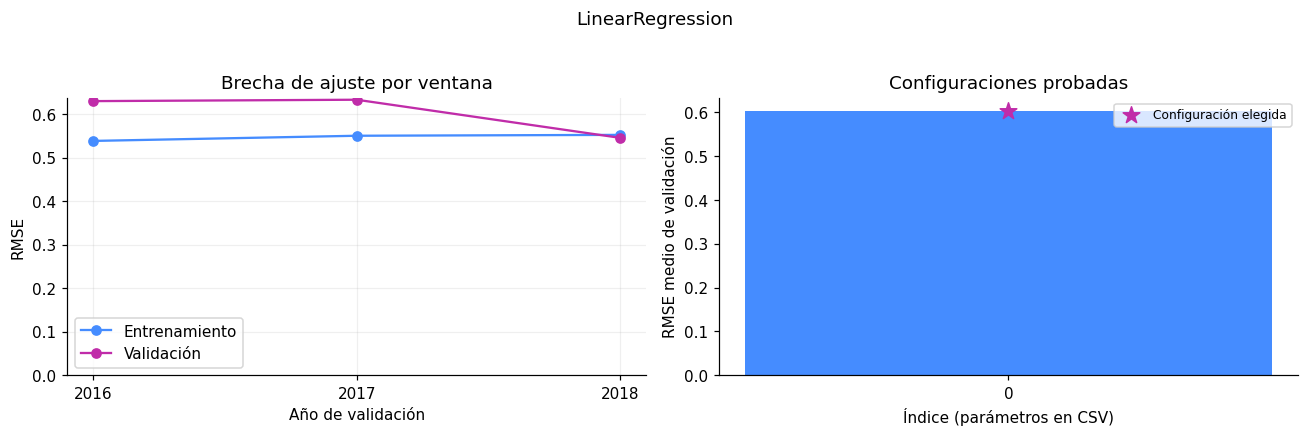

In [ ]:
linear_search = fit_candidate('LinearRegression', LinearRegression(), {}, scale=True)

### Random Forest Regressor


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2
0,RandomForest,0.5161,0.0611,0.4134,0.7881


Mejores parámetros: {'model__max_depth': None, 'model__min_samples_leaf': 2}


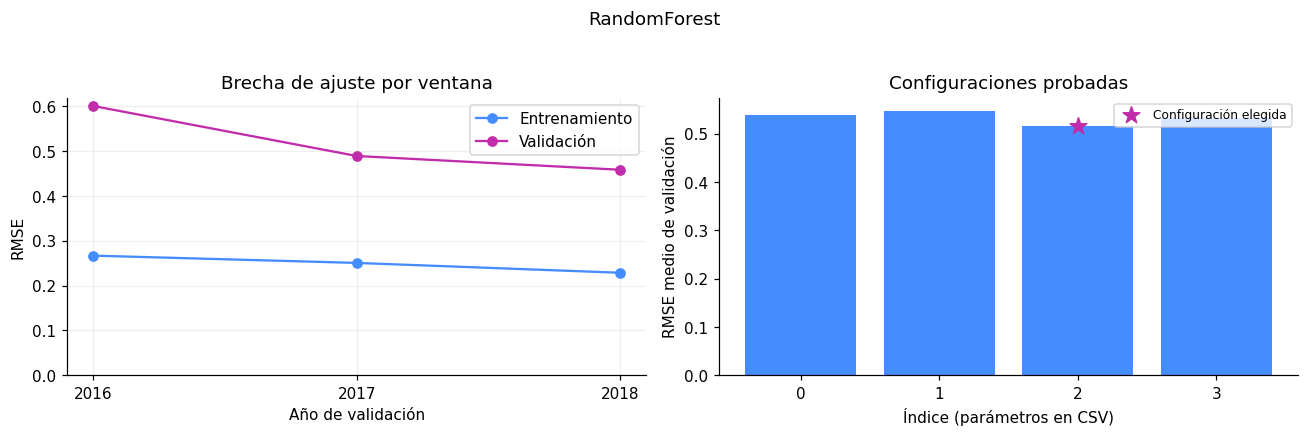

In [5]:
forest_search = fit_candidate('RandomForest', RandomForestRegressor(n_estimators=250, random_state=SEED, n_jobs=2),
                              {'model__max_depth': [4, None], 'model__min_samples_leaf': [2, 5]})


### Decision Tree Regressor


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2
0,DecisionTree,0.6183,0.072,0.4826,0.696


Mejores parámetros: {'model__max_depth': 8, 'model__min_samples_leaf': 10}


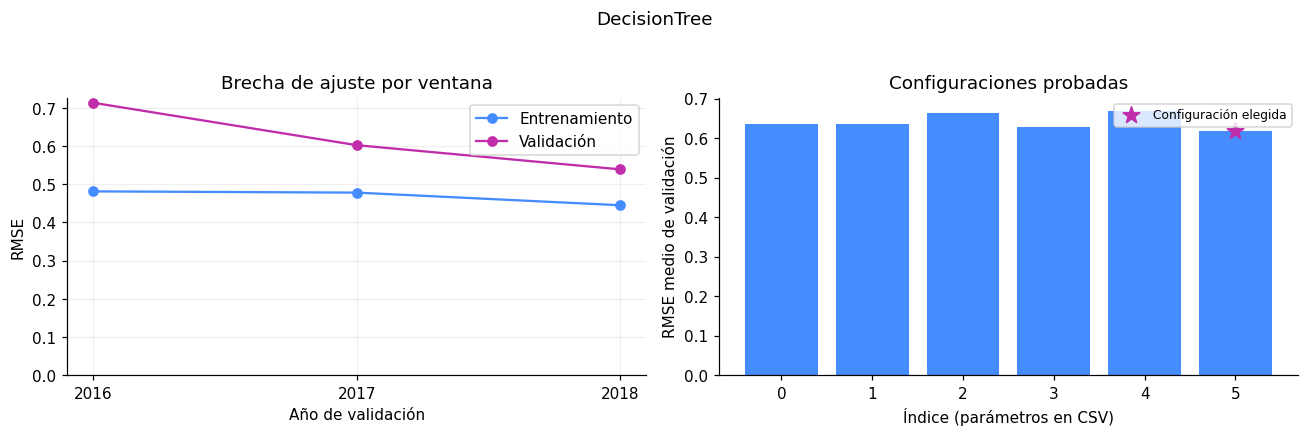

In [6]:
tree_search = fit_candidate('DecisionTree', DecisionTreeRegressor(random_state=SEED),
                            {'model__max_depth': [3, 5, 8], 'model__min_samples_leaf': [5, 10]})


### XGBoost


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2
0,XGBoost,0.5413,0.0799,0.4299,0.7653


Mejores parámetros: {'model__max_depth': 3, 'model__n_estimators': 250}


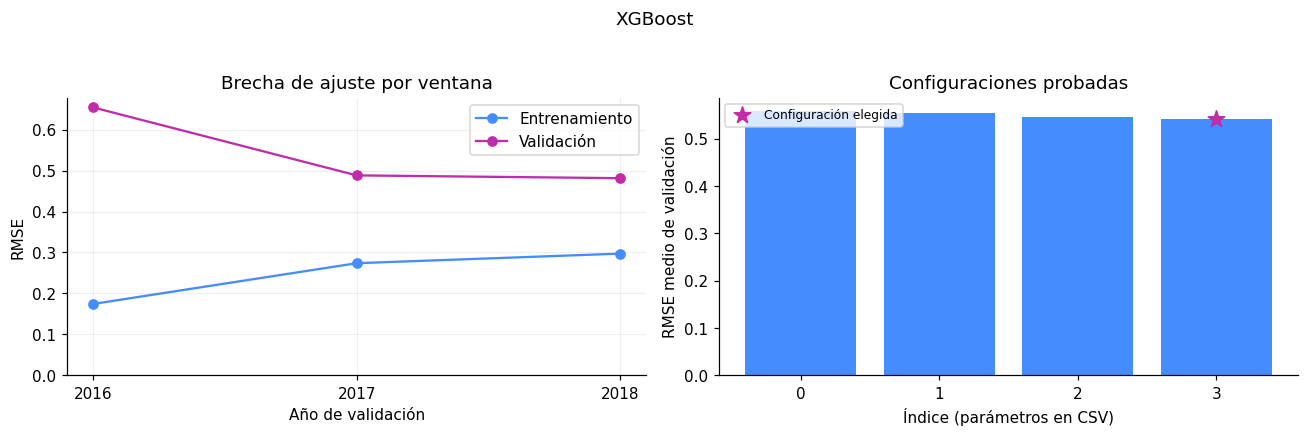

In [7]:
xgb_search = fit_candidate('XGBoost', XGBRegressor(objective='reg:squarederror', tree_method='hist',
                           learning_rate=.05, random_state=SEED, n_jobs=2, reg_lambda=1),
                           {'model__n_estimators': [100, 250], 'model__max_depth': [2, 3]})


### LightGBM


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2
0,LightGBM,0.5571,0.0887,0.4494,0.7507


Mejores parámetros: {'model__n_estimators': 100, 'model__num_leaves': 15}


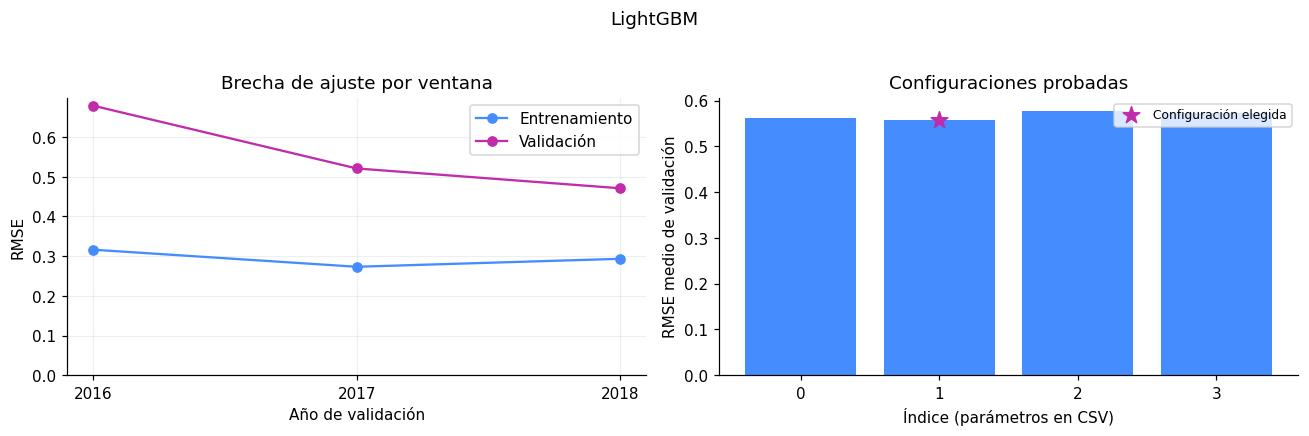

In [8]:
lgbm_search = fit_candidate('LightGBM', LGBMRegressor(objective='regression', learning_rate=.05,
                            min_child_samples=15, verbosity=-1, random_state=SEED, n_jobs=2,
                            deterministic=True, force_col_wise=True),
                            {'model__n_estimators': [100, 250], 'model__num_leaves': [7, 15]})


## 3. Selección previa a la prueba final

Ordenamos por RMSE medio de validación, con MAE como desempate. La desviación de
RMSE describe variación entre tres años; no es un intervalo de confianza. La media
de R² resume tres evaluaciones separadas, no un R² conjunto. Los errores de validación
ya participaron en la selección: el año 2019 es la evaluación final reservada.


,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2
0,RandomForest,0.5161,0.0611,0.4134,0.7881
1,XGBoost,0.5413,0.0799,0.4299,0.7653
2,LightGBM,0.5571,0.0887,0.4494,0.7507
3,LinearRegression,0.6031,0.0405,0.4803,0.7129
4,DecisionTree,0.6183,0.0720,0.4826,0.6960


Modelo seleccionado antes de evaluar 2019: RandomForest
RMSE medio de referencia: 1.1273


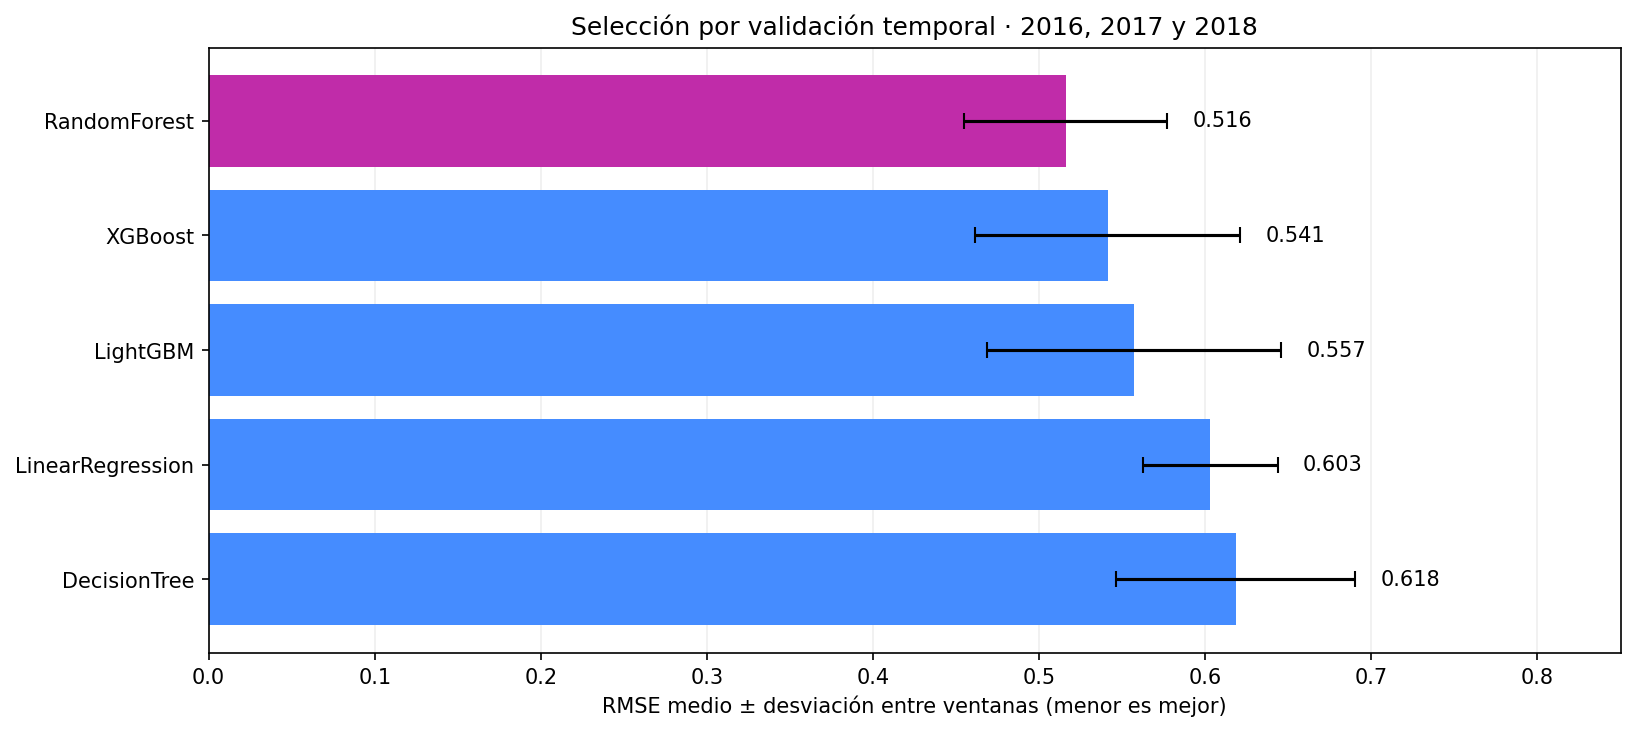

In [9]:
validation_table = pd.DataFrame(validation_rows).sort_values(['cv_rmse', 'cv_mae', 'model']).reset_index(drop=True)
best_name = validation_table.iloc[0]['model']
best_development_model = searches[best_name].best_estimator_
display(validation_table.round(4))
validation_table.to_csv(TABLE_DIR / 'validation_results.csv', index=False)
print('Modelo seleccionado antes de evaluar 2019:', best_name)
# La referencia usa las mismas ventanas.
baseline_cv = []
for train_idx, valid_idx in folds:
    baseline = DummyRegressor(strategy='mean').fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    baseline_cv.append(metrics(y_dev.iloc[valid_idx], baseline.predict(X_dev.iloc[valid_idx])))
print('RMSE medio de referencia:', round(np.mean([m['rmse'] for m in baseline_cv]), 4))

fig, ax = plt.subplots(figsize=(11, 5))
ordered = validation_table.iloc[::-1]
bars = ax.barh(ordered.model, ordered.cv_rmse,
               color=['#c02ca9' if name == best_name else '#458cff' for name in ordered.model],
               xerr=ordered.cv_rmse_std, capsize=4)
for bar, value, spread in zip(bars, ordered.cv_rmse, ordered.cv_rmse_std):
    ax.text(value + spread + .015, bar.get_y()+bar.get_height()/2, f'{value:.3f}', va='center')
ax.set(title='Selección por validación temporal · 2016, 2017 y 2018',
       xlabel='RMSE medio ± desviación entre ventanas (menor es mejor)', xlim=(0, .85))
ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
finish(fig, 'validation_model_comparison.png')


## 4. Evaluación 2019 y gráficas de cada modelo

Todos los estimadores ya están ajustados con 2015–2018. Mostramos los resultados
2019 de los cinco modelos para comparación, sin cambiar al ganador elegido en
validación. Una tabla incluye entrenamiento y prueba para detectar sobreajuste.
Cada modelo tiene observado frente a predicho y residuos frente a predicción;
residuo = observado − predicho. La diagonal y la línea cero son referencias ideales.


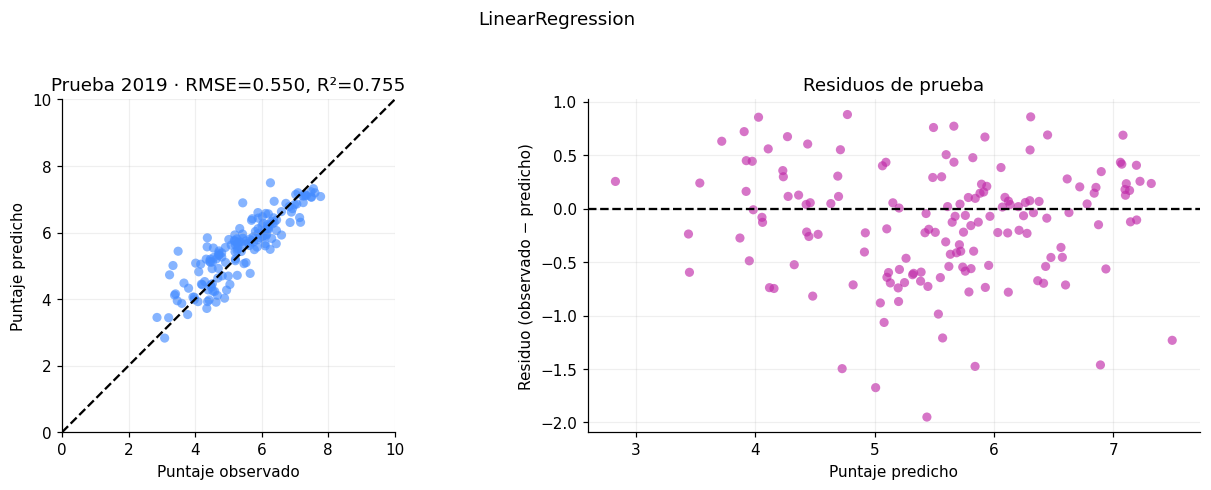

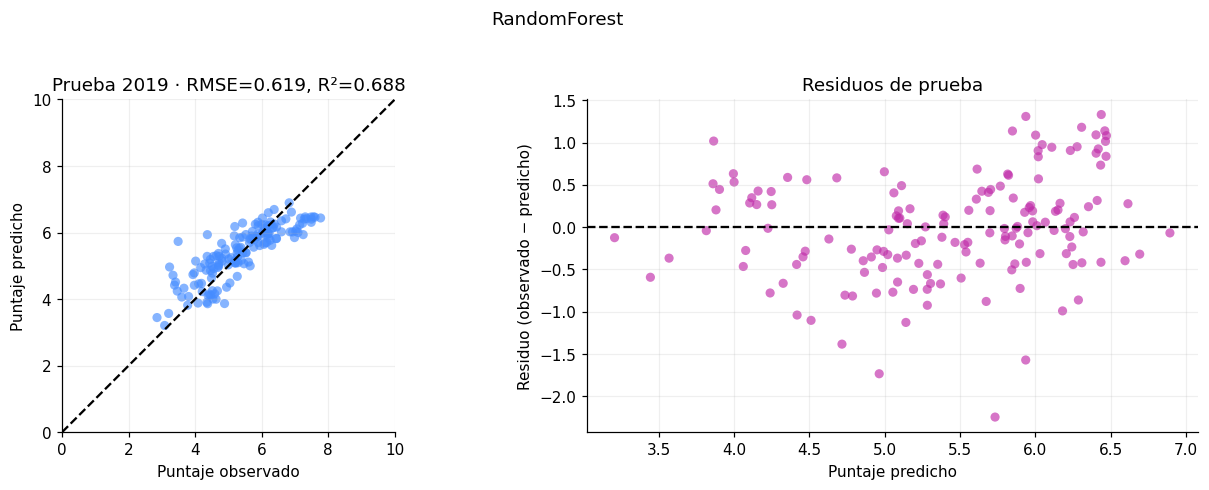

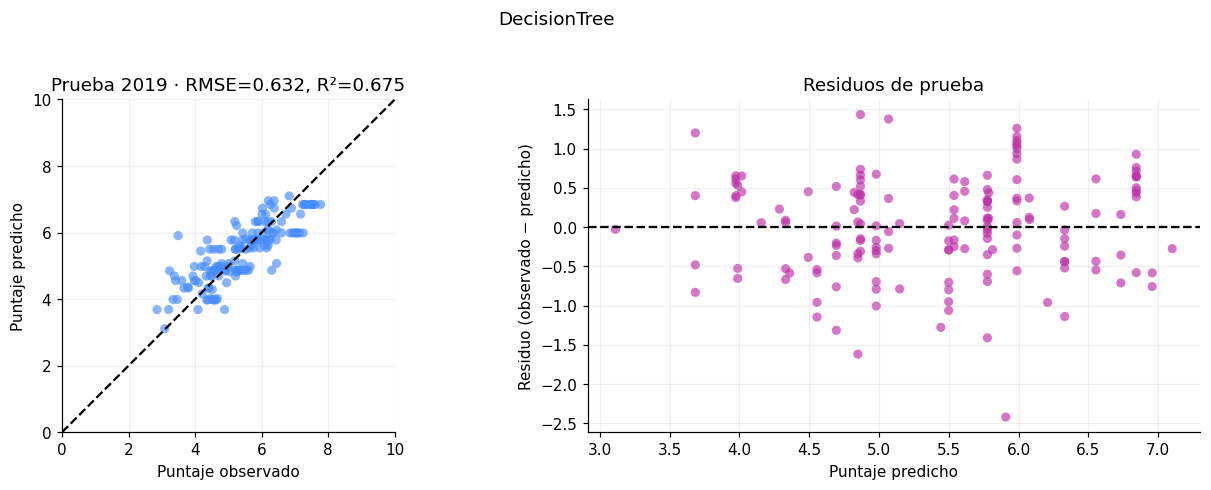

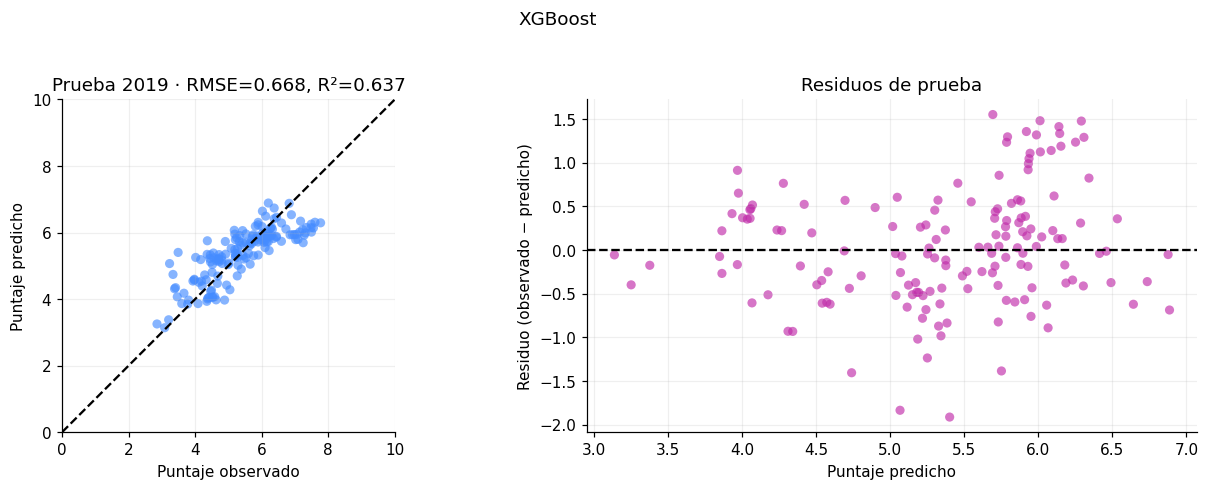

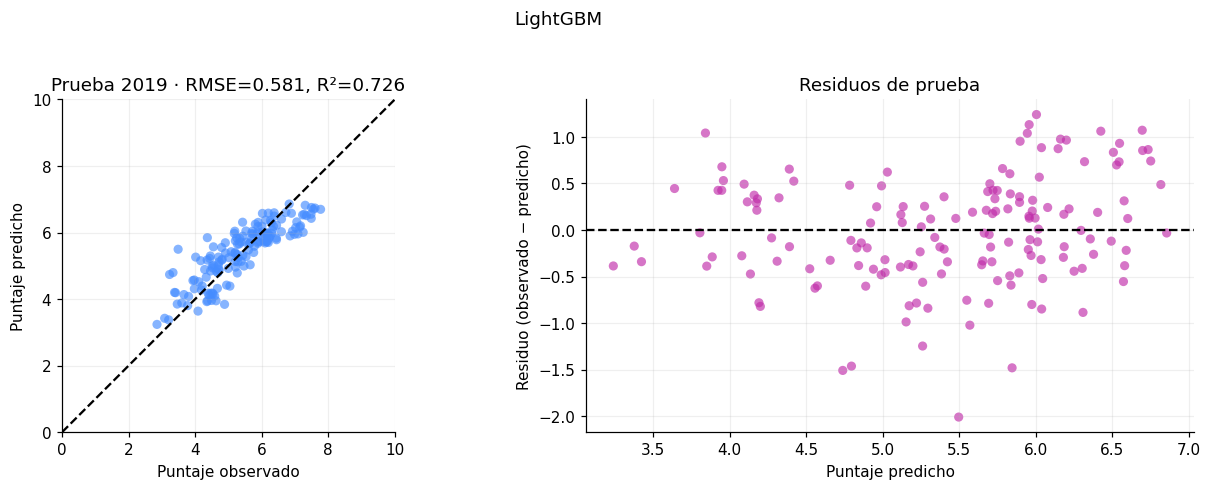

,model,cv_rmse,cv_rmse_std,cv_mae,cv_r2,train_rmse,train_mae,train_r2,test_rmse,test_mae,test_r2,selected_by_validation
0,RandomForest,0.5161,0.0611,0.4134,0.7881,0.2195,0.1685,0.9623,0.6193,0.4833,0.6885,True
1,XGBoost,0.5413,0.0799,0.4299,0.7653,0.3274,0.2544,0.9162,0.6681,0.5268,0.6374,False
2,LightGBM,0.5571,0.0887,0.4494,0.7507,0.3105,0.2466,0.9246,0.5809,0.4679,0.7259,False
3,LinearRegression,0.6031,0.0405,0.4803,0.7129,0.5484,0.4271,0.7649,0.5497,0.4242,0.7546,False
4,DecisionTree,0.6183,0.0720,0.4826,0.6960,0.4236,0.3288,0.8597,0.6324,0.5071,0.6752,False


,model,rmse,mae,r2
0,DummyMean,1.1101,0.9164,-0.001


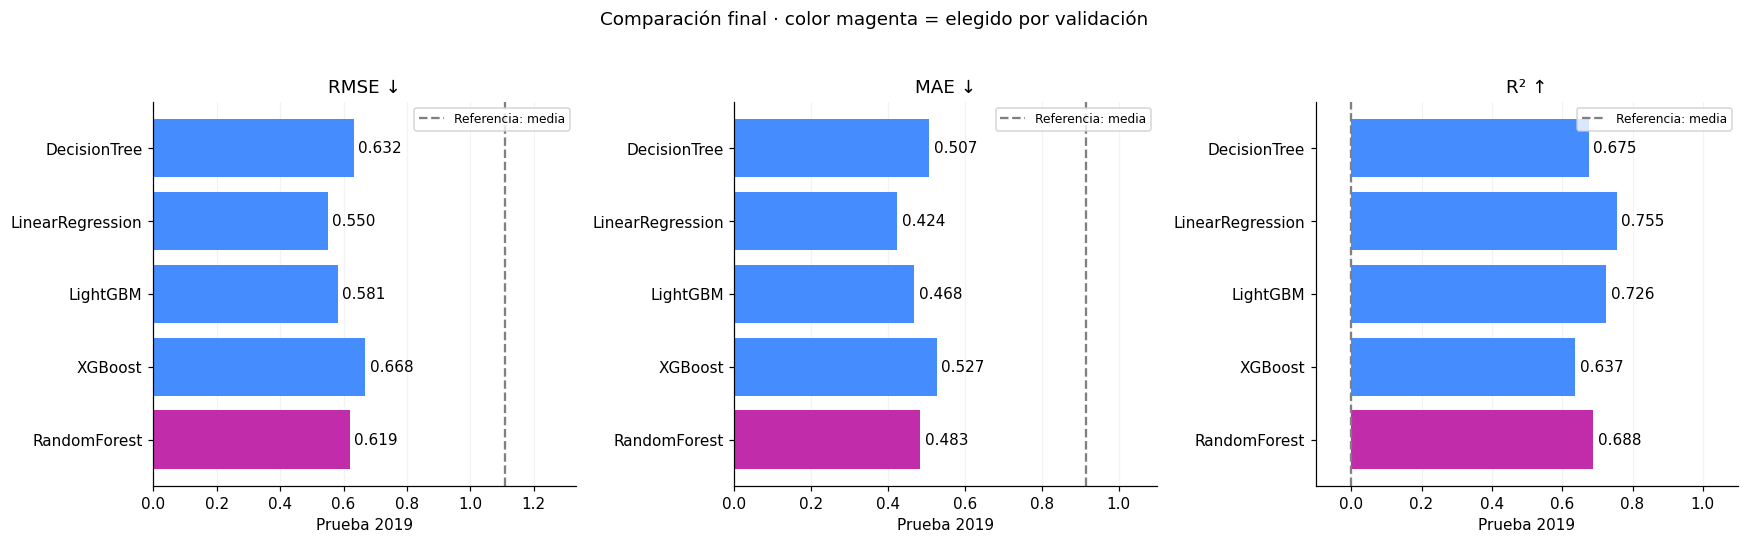

In [10]:
test_rows = []
predictions = test[['country', 'year', TARGET]].copy()
for name, search in searches.items():
    estimator = search.best_estimator_
    train_scores = metrics(y_dev, estimator.predict(X_dev))
    pred = estimator.predict(X_test)
    scores = metrics(y_test, pred)
    assert np.isfinite(pred).all()
    test_rows.append({'model': name, **{f'train_{k}': v for k, v in train_scores.items()},
                      **{f'test_{k}': v for k, v in scores.items()}})
    predictions[name] = pred
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(y_test, pred, alpha=.65, color='#458cff', edgecolors='none')
    axes[0].plot([0, 10], [0, 10], '--', color='black')
    axes[0].set(xlabel='Puntaje observado', ylabel='Puntaje predicho', xlim=(0, 10), ylim=(0, 10),
                title=f'Prueba 2019 · RMSE={scores["rmse"]:.3f}, R²={scores["r2"]:.3f}')
    axes[0].set_aspect('equal', adjustable='box')
    axes[1].scatter(pred, y_test.to_numpy()-pred, alpha=.65, color='#c02ca9', edgecolors='none')
    axes[1].axhline(0, color='black', linestyle='--')
    axes[1].set(xlabel='Puntaje predicho', ylabel='Residuo (observado − predicho)', title='Residuos de prueba')
    for ax in axes: ax.grid(alpha=.2)
    fig.suptitle(name)
    finish(fig, f'{name}_test_diagnostics.png')
baseline = DummyRegressor(strategy='mean').fit(X_dev, y_dev)
baseline_test = metrics(y_test, baseline.predict(X_test))
results = validation_table.merge(pd.DataFrame(test_rows), on='model', validate='one_to_one')
results['selected_by_validation'] = results.model.eq(best_name)
display(results.round(4))
display(pd.DataFrame([{'model': 'DummyMean', **baseline_test}]).round(4))
results.to_csv(TABLE_DIR / 'model_comparison.csv', index=False)
predictions.to_csv(TABLE_DIR / 'test_predictions_2019.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric, title in zip(axes, ['rmse', 'mae', 'r2'], ['RMSE ↓', 'MAE ↓', 'R² ↑']):
    values = results[f'test_{metric}']
    bars = ax.barh(results.model, values, color=['#c02ca9' if n==best_name else '#458cff' for n in results.model])
    ax.bar_label(bars, fmt='%.3f', padding=3)
    ax.axvline(baseline_test[metric], color='gray', linestyle='--', label='Referencia: media')
    ax.set(title=title, xlabel='Prueba 2019')
    if metric!='r2': ax.set_xlim(0, max(values.max(), baseline_test[metric])*1.2)
    else: ax.set_xlim(min(0, values.min(), baseline_test[metric])-.1, 1.1)
    ax.legend(fontsize=8); ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
fig.suptitle('Comparación final · color magenta = elegido por validación')
finish(fig, 'model_comparison.png')


## 5. Diagnóstico del modelo seleccionado

El histograma y el Q–Q permiten explorar asimetrías y colas de residuos; no se asume
normalidad para predecir. Mostramos errores por país y por disponibilidad de historial.
La importancia por permutación mide cuánto aumenta RMSE al desordenar una variable
en 2019 (20 repeticiones). Variables correlacionadas pueden compartir importancia;
las barras no implican causalidad y su dispersión no es incertidumbre de generalización.
Estos diagnósticos describen la prueba; cualquier ajuste posterior requerirá otra evaluación.

R² no se calcula para subgrupos de una sola observación; se muestra como NaN.


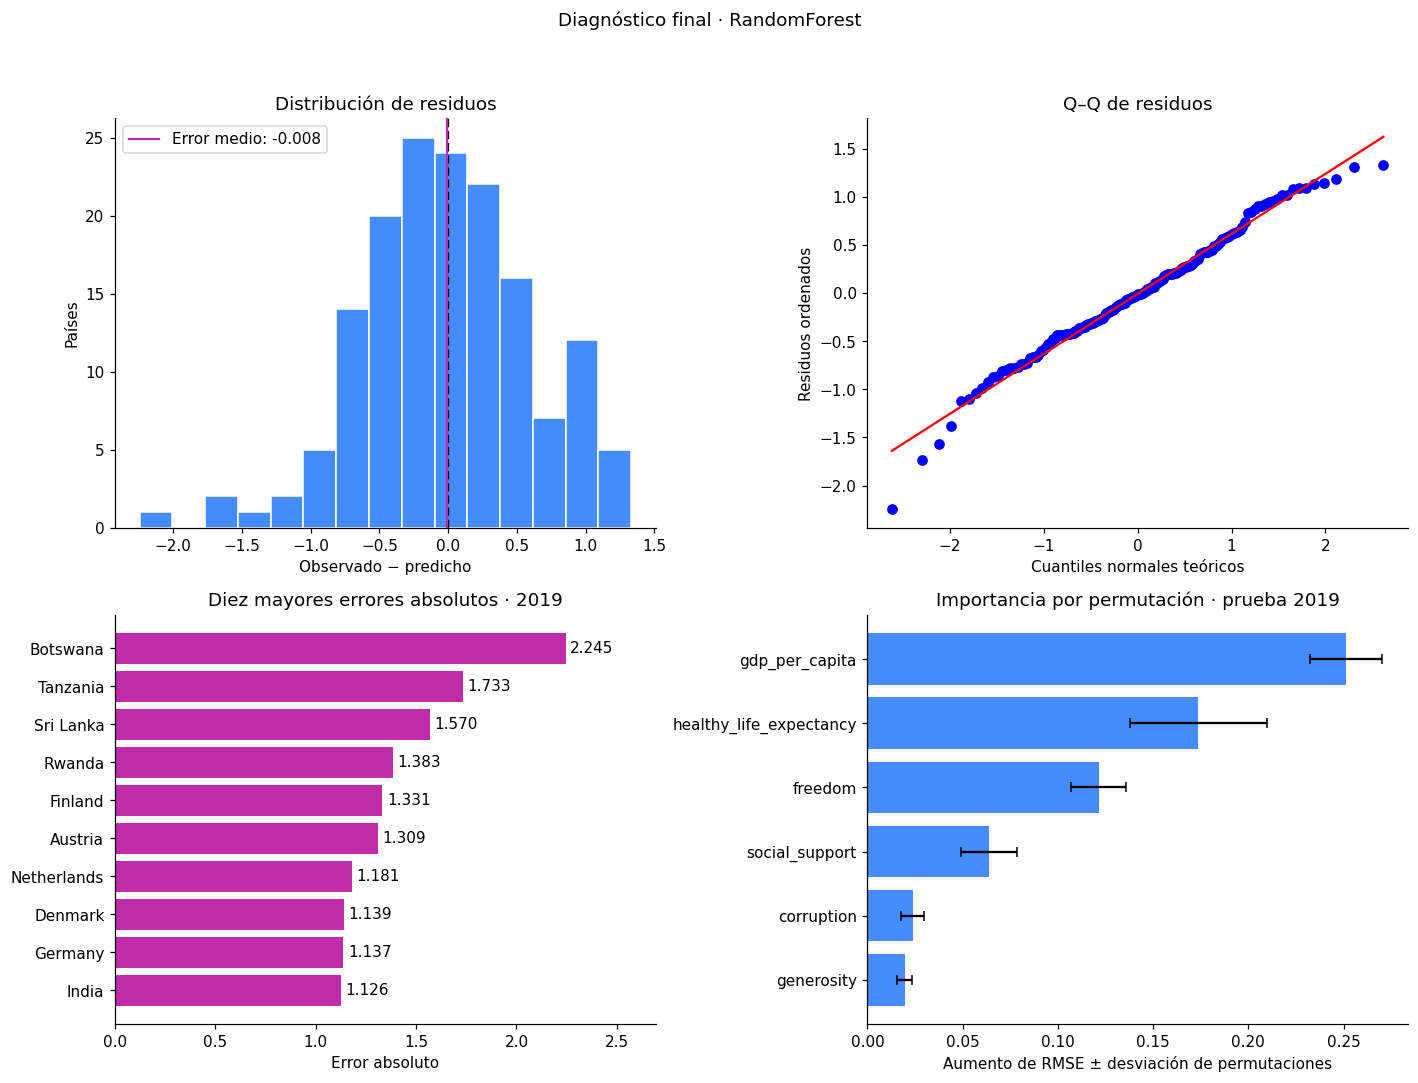

,country_history,rows,rmse,mae,r2
0,Sin historial,1,0.2653,0.2653,NaN
1,Con historial,155,0.6209,0.4847,0.6875


Seleccionado: RandomForest; RMSE CV=0.5161; RMSE 2019=0.6193; MAE=0.4833; R²=0.6885
RMSE de referencia 2019: 1.1101


In [11]:
best_predictions = predictions[best_name].to_numpy()
residuals = y_test.to_numpy() - best_predictions
errors = test[['country', 'year', TARGET]].assign(predicted=best_predictions, residual=residuals,
             absolute_error=np.abs(residuals), seen_in_development=test.country.isin(development.country))
errors.to_csv(TABLE_DIR / 'best_model_errors_2019.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].hist(residuals, bins=15, color='#458cff', edgecolor='white')
axes[0, 0].axvline(0, color='black', linestyle='--')
axes[0, 0].axvline(residuals.mean(), color='#c02ca9', label=f'Error medio: {residuals.mean():+.3f}')
axes[0, 0].set(title='Distribución de residuos', xlabel='Observado − predicho', ylabel='Países'); axes[0, 0].legend()
stats.probplot(residuals, dist='norm', plot=axes[0, 1])
axes[0, 1].set(title='Q–Q de residuos', xlabel='Cuantiles normales teóricos', ylabel='Residuos ordenados')
worst = errors.nlargest(10, 'absolute_error').sort_values('absolute_error')
bars = axes[1, 0].barh(worst.country, worst.absolute_error, color='#c02ca9')
axes[1, 0].bar_label(bars, fmt='%.3f', padding=3)
axes[1, 0].set(title='Diez mayores errores absolutos · 2019', xlabel='Error absoluto', xlim=(0, worst.absolute_error.max()*1.2))
importance = permutation_importance(best_development_model, X_test, y_test,
                scoring='neg_root_mean_squared_error', n_repeats=20, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': FEATURES, 'rmse_increase': importance.importances_mean,
                                  'std': importance.importances_std}).sort_values('rmse_increase')
axes[1, 1].barh(importance_table.feature, importance_table.rmse_increase,
                xerr=importance_table['std'], color='#458cff', capsize=3)
axes[1, 1].axvline(0, color='gray', linewidth=.8)
axes[1, 1].set(title='Importancia por permutación · prueba 2019', xlabel='Aumento de RMSE ± desviación de permutaciones')
fig.suptitle(f'Diagnóstico final · {best_name}')
finish(fig, 'best_model_diagnostics.png')
importance_table.to_csv(TABLE_DIR / 'best_model_permutation_importance.csv', index=False)
subgroup_rows = []
for seen, group in errors.groupby('seen_in_development'):
    subgroup_rows.append({'country_history': 'Con historial' if seen else 'Sin historial',
                          'rows': len(group), **metrics(group[TARGET], group.predicted)})
display(pd.DataFrame(subgroup_rows).round(4))
pd.DataFrame(subgroup_rows).to_csv(TABLE_DIR / 'best_model_metrics_by_country_history.csv', index=False)
selected_scores = results.loc[results.model.eq(best_name)].iloc[0]
print(f'Seleccionado: {best_name}; RMSE CV={selected_scores.cv_rmse:.4f}; '
      f'RMSE 2019={selected_scores.test_rmse:.4f}; MAE={selected_scores.test_mae:.4f}; R²={selected_scores.test_r2:.4f}')
print('RMSE de referencia 2019:', round(baseline_test['rmse'], 4))


### Lectura de los resultados

Random Forest se selecciona por **RMSE medio de validación = 0,516** frente a
0,603 de la regresión lineal. En 2019 obtiene RMSE **0,619**, MAE **0,483** y
R² **0,688**, mejor que la referencia constante (RMSE 1,110).

La regresión lineal consigue el mejor resultado **en el año de prueba**:
RMSE 0,550, MAE 0,424 y R² 0,755. El orden cambia entre validación y prueba;
no hay un ganador universal. Conservamos Random Forest según el criterio definido
antes de ver 2019. Cambiarlo ahora usando ese año convertiría la prueba en selección.
La brecha de Random Forest entre entrenamiento (RMSE 0,219) y prueba (0,619)
indica que el ajuste al entrenamiento es mucho mejor que su generalización temporal.

El error medio de Random Forest es aproximadamente −0,008, pero un promedio cercano
a cero oculta errores nacionales: Botswana presenta el mayor error absoluto (2,245).
PIB per cápita y esperanza de vida saludable muestran las mayores importancias por
permutación. Son asociaciones predictivas, no explicaciones causales.


## 6. Guardar `model.pkl` y verificar su uso

El modelo evaluado permanece en `best_development_model`. Para el artefacto final,
reentrenamos su configuración seleccionada con **2015–2019 completos**, sin volver
a elegir hiperparámetros. `models/model.pkl` contiene un pipeline y acepta un DataFrame
con las seis columnas predictoras. Las métricas 2019 pertenecen al ajuste 2015–2018,
no al reentrenamiento final. Conservamos versiones, columnas, hash de datos y resultados
en `models/model_metadata.json`. Pickle debe cargarse solo desde archivos de confianza
y con las mismas versiones de dependencias. El ejemplo verifica las predicciones
después de volver a cargar el archivo; no es una nueva evaluación del modelo.


In [12]:
final_model = clone(best_development_model).fit(data[FEATURES], data[TARGET])
model_path = MODEL_DIR / 'model.pkl'
with model_path.open('wb') as file:
    pickle.dump(final_model, file, protocol=pickle.HIGHEST_PROTOCOL)
with model_path.open('rb') as file:
    loaded_model = pickle.load(file)
example = data[FEATURES].head(5)
np.testing.assert_allclose(loaded_model.predict(example), final_model.predict(example), rtol=1e-12, atol=1e-12)
assert loaded_model.feature_names_in_.tolist() == FEATURES
metadata = {
    'selected_model': best_name, 'selection_metric': 'lowest mean temporal validation RMSE; MAE tie-break',
    'features': FEATURES, 'target': TARGET, 'excluded_identifiers': ['country', 'year'],
    'validation_folds': fold_summary, 'evaluation_training_years': [2015, 2016, 2017, 2018],
    'test_year': 2019, 'test_rows': len(test),
    'selected_validation_metrics': validation_table.iloc[0].to_dict(),
    'selected_test_metrics': {k: float(selected_scores[f'test_{k}']) for k in ['rmse', 'mae', 'r2']},
    'baseline_test_metrics': baseline_test,
    'best_parameters': searches[best_name].best_params_,
    'saved_model_training_years': sorted(data.year.unique().tolist()), 'saved_model_training_rows': len(data),
    'saved_model_evaluation': 'No independent holdout after final refit; reported test scores use 2015–2018 fit',
    'data_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(), 'random_seed': SEED,
    'python_version': platform.python_version(),
    'package_versions': {name: importlib.metadata.version(name) for name in
                         ['scikit-learn', 'xgboost', 'lightgbm', 'pandas', 'numpy', 'scipy']},
}
(MODEL_DIR / 'model_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
print('Modelo guardado y recargado correctamente:', model_path)
display(pd.DataFrame({'example_prediction': loaded_model.predict(example)}))


Modelo guardado y recargado correctamente: d:\UAO\Quinto Semestre\etl\workshop-3\models\model.pkl


,example_prediction
0,3.663504
1,4.951949
2,5.348681
3,4.046260
4,6.459696


## Referencias de implementación

- [Métricas de regresión de scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html).
- [API XGBRegressor](https://xgboost.readthedocs.io/en/stable/python/python_api.html).
- [API LGBMRegressor](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html).
